# 04 · Propagation Statistics Extension

Question: does adding explicit propagation statistics to the best GNN improve fake-news classification?

| Variant | Input to the classifier |
|---|---|
| Best GNN | graph vector (+ root vector, as in notebook 03) |
| Best GNN + statistics | graph vector (+ root vector) + projected propagation statistics |

The best GNN per dataset is the one with the highest validation macro-F1 in notebook 03. Both variants use the same architecture, splits, seeds and training rules. Statistics are log-transformed (counts) and standardised with training graphs only.

This is a small extension of an existing model, not a new architecture. Results are reported as measured, whether or not the extension helps.

## 1 · Setup

In [1]:
import sys, os, json, time, platform, warnings, random, logging, gc
from pathlib import Path
import psutil

import numpy as np
import networkx as nx
import pandas as pd
import scipy
import scipy.sparse as sp
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, precision_recall_fscore_support)

try:
    from tqdm.auto import tqdm
except ImportError:
    print("tqdm not installed -> progress bars disabled.  Install with: pip install tqdm")
    def tqdm(iterable=None, **kwargs):
        return iterable

IMPORT_PROBLEMS = []

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError as exc:
    torch = nn = F = None
    IMPORT_PROBLEMS.append(("PyTorch", repr(exc)))

try:
    import torch_geometric
    from torch_geometric.data import Data
    from torch_geometric.loader import DataLoader
    from torch_geometric.nn import GCNConv, GATConv, SAGEConv, global_mean_pool, global_max_pool
    from torch_geometric.utils import to_undirected
except Exception as exc:
    torch_geometric = None
    IMPORT_PROBLEMS.append(("PyTorch Geometric (Data, DataLoader, GCNConv, GATConv, SAGEConv, pooling)", repr(exc)))

try:
    from torch_geometric.datasets import UPFD
    PYG_IMPORT_ERROR = None
except Exception as exc:
    UPFD = None
    PYG_IMPORT_ERROR = repr(exc)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)


def rss_mb():
    return psutil.Process().memory_info().rss / 1e6

In [2]:
INSTALL_HELP = "Install PyTorch from https://pytorch.org/get-started/locally/ and then run: pip install torch_geometric tqdm"

versions = {"Python": sys.version.split()[0], "Platform": platform.platform(), "NumPy": np.__version__,
            "Pandas": pd.__version__, "SciPy": scipy.__version__, "scikit-learn": sklearn.__version__,
            "PyTorch": torch.__version__ if torch is not None else "NOT INSTALLED",
            "PyG": torch_geometric.__version__ if torch_geometric is not None else "NOT AVAILABLE"}
for k, v in versions.items():
    print(f"{k:<14}{v}")

if IMPORT_PROBLEMS:
    raise RuntimeError("Missing packages: " + ", ".join(n for n, _ in IMPORT_PROBLEMS) + "\n" + INSTALL_HELP)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("Device: CUDA ->", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    print("Device: CPU")

Python        3.13.13
Platform      Windows-11-10.0.26200-SP0
NumPy         2.4.3
Pandas        2.3.3
SciPy         1.17.1
scikit-learn  1.8.0
PyTorch       2.11.0+cpu
PyG           2.8.1
Device: CPU


In [3]:
SEED = 42
FEATURE = "bert"
EXPECTED_FEATURE_DIM = 768
DATASETS = ["politifact", "gossipcop"]
DATASET_TITLES = {"politifact": "PolitiFact", "gossipcop": "GossipCop"}
SPLITS = ["train", "val", "test"]


FAKE_CLASS_INDEX = None
if FAKE_CLASS_INDEX is None:
    CLASS_NAMES = {0: "class 0", 1: "class 1"}
else:
    CLASS_NAMES = {FAKE_CLASS_INDEX: "fake", 1 - FAKE_CLASS_INDEX: "real"}
CLASS_COLORS = {0: "#0072B2", 1: "#D55E00"}


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "upfd").is_dir():
            return candidate
    for candidate in [start, *start.parents]:
        if (candidate / "notebooks").is_dir() and (candidate / "README.md").is_file():
            return candidate
    return start.parent if start.name == "notebooks" else start


PROJECT_ROOT = find_project_root()
UPFD_ROOT = PROJECT_ROOT / "data" / "upfd"
RESULTS_DIR = PROJECT_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"
LOGS_DIR = RESULTS_DIR / "logs"
CHECKPOINTS_DIR = RESULTS_DIR / "checkpoints"
for _d in (METRICS_DIR, FIGURES_DIR, LOGS_DIR, CHECKPOINTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Project root     :", PROJECT_ROOT)
print("UPFD data root   :", UPFD_ROOT, "(found)" if UPFD_ROOT.is_dir() else "(NOT FOUND)")
if not UPFD_ROOT.is_dir():
    raise FileNotFoundError(
        f"Could not find '{UPFD_ROOT}'. Start Jupyter from inside the project folder "
        "(e.g. `cd FakeNews-detection-GNN` then `jupyter lab`) so that data/upfd/ can be located."
    )


SAVED_ARTIFACTS = []


def _json_default(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, Path):
        return str(obj)
    return str(obj)


def _register(path, kind):
    path = Path(path)
    try:
        shown = str(path.relative_to(PROJECT_ROOT))
    except ValueError:
        shown = str(path)
    SAVED_ARTIFACTS.append({"kind": kind, "path": shown, "size_kB": round(path.stat().st_size / 1024, 1)})


def save_figure(fig, path, dpi=150):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    _register(path, "figure")
    return path


def save_dataframe(df, path, index=False):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=index)
    _register(path, "csv")
    return path


def save_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=_json_default), encoding="utf-8")
    _register(path, "json")
    return path

Working directory: C:\Users\shara\FakeNews-detection-GNN\notebooks
Project root     : C:\Users\shara\FakeNews-detection-GNN
UPFD data root   : C:\Users\shara\FakeNews-detection-GNN\data\upfd (found)


In [4]:
GNN_METRICS_DIR = METRICS_DIR / "gnn"
for f in ("gnn_config.json", "best_gnn_by_validation.json"):
    if not (GNN_METRICS_DIR / f).is_file():
        raise FileNotFoundError(f"{f} not found. Run notebook 03 first.")
GCFG = json.loads((GNN_METRICS_DIR / "gnn_config.json").read_text())
BEST_GNN = json.loads((GNN_METRICS_DIR / "best_gnn_by_validation.json").read_text())["best_gnn_by_dataset"]

SETTING, EDGE_MODE, READOUT = GCFG["setting"], GCFG["edge_mode"], GCFG["readout"]
NUM_LAYERS, ROOT_FUSION, CFG = GCFG["num_layers"], GCFG["root_fusion"], GCFG["cfg"]
BATCH_SIZE, EVAL_BATCH_SIZE, SEEDS = GCFG["batch_size"], GCFG["eval_batch_size"], GCFG["seeds"]
NUM_WORKERS = 0

EXT_METRICS_DIR = METRICS_DIR / "extension"
EXT_FIG_DIR = FIGURES_DIR / "extension"
for _d in (EXT_METRICS_DIR, EXT_FIG_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


print("Setting :", SETTING)
print("Seeds   :", SEEDS)
print("Best GNN:", BEST_GNN)

Setting : L1_max_root_as_stored
Seeds   : [42, 43, 44, 45, 46]
Best GNN: {'politifact': 'GraphSAGE', 'gossipcop': 'GraphSAGE'}


## 2 · Data

In [5]:
REQUIRED_FILES = [
    "A.txt", "graph_labels.npy", "node_graph_id.npy",
    "train_idx.npy", "val_idx.npy", "test_idx.npy",
]
FEATURE_FILE = f"new_{FEATURE}_feature.npz"


def detect_layout(name, root=UPFD_ROOT):
    base = Path(root) / name
    required = REQUIRED_FILES + [FEATURE_FILE]
    problems = []
    for label, directory in (("raw", base / "raw"), ("flat", base)):
        if not directory.is_dir():
            problems.append(f"  - {directory}: directory does not exist")
            continue
        missing = [f for f in required if not (directory / f).is_file()]
        if not missing:
            return label, directory
        problems.append(f"  - {directory}: missing {missing}")
    raise FileNotFoundError(
        f"Could not find a complete UPFD '{name}' dataset under {base}.\n"
        + "\n".join(problems)
        + "\nThe files must be either directly inside that folder or inside its 'raw/' sub-folder."
    )


def load_feature_matrix(path):
    path = Path(path)
    try:
        X = sp.load_npz(path)
        kind = f"scipy.sparse ({X.format})"
    except Exception as sparse_error:
        try:
            with np.load(path, allow_pickle=False) as archive:
                arrays = {k: archive[k] for k in archive.files}
        except Exception as dense_error:
            raise ValueError(
                f"{path.name} is neither a SciPy sparse archive ({sparse_error!r}) "
                f"nor a readable NumPy archive ({dense_error!r})."
            )
        candidates = [k for k, v in arrays.items() if v.ndim == 2]
        if len(candidates) != 1:
            raise ValueError(
                f"{path.name} is not a SciPy sparse archive ({sparse_error!r}) and contains "
                f"{len(candidates)} two-dimensional arrays (keys: {list(arrays)}), so the feature "
                "matrix cannot be identified unambiguously."
            )
        X = sp.csr_matrix(arrays[candidates[0]])
        kind = f"dense array stored under key '{candidates[0]}'"
    return X.tocsr().astype(np.float32, copy=False), kind


def load_upfd_raw(name, load_features=True):
    layout, d = detect_layout(name)

    node_graph_id = np.load(d / "node_graph_id.npy", allow_pickle=False).reshape(-1).astype(np.int64)
    n_nodes = int(node_graph_id.shape[0])

    y_raw = np.load(d / "graph_labels.npy", allow_pickle=False).reshape(-1)
    classes_raw, y = np.unique(y_raw, return_inverse=True)
    y = np.asarray(y, dtype=np.int64).reshape(-1)
    n_graphs = int(y.shape[0])

    if node_graph_id.min() < 0 or node_graph_id.max() >= n_graphs:
        raise ValueError(
            f"[{name}] node_graph_id.npy contains ids in [{node_graph_id.min()}, {node_graph_id.max()}] "
            f"but graph_labels.npy describes {n_graphs} graphs (valid ids: 0..{n_graphs - 1})."
        )
    if np.any(np.diff(node_graph_id) < 0):
        raise ValueError(
            f"[{name}] node_graph_id.npy is not sorted, i.e. the nodes of one graph are not contiguous. "
            "The PyG-style slicing used here (and by PyG itself) would be wrong."
        )
    node_counts = np.bincount(node_graph_id, minlength=n_graphs)
    if np.any(node_counts == 0):
        raise ValueError(f"[{name}] {(node_counts == 0).sum()} graph id(s) own zero nodes.")
    node_slice = np.concatenate([[0], np.cumsum(node_counts)]).astype(np.int64)


    edges_raw = pd.read_csv(d / "A.txt", header=None, sep=",", skipinitialspace=True).to_numpy()
    if edges_raw.ndim != 2 or edges_raw.shape[1] != 2:
        raise ValueError(f"[{name}] A.txt should have exactly two comma-separated columns, got shape {edges_raw.shape}.")
    edges_raw = edges_raw.astype(np.int64)
    if edges_raw.min() < 0 or edges_raw.max() >= n_nodes:
        raise ValueError(
            f"[{name}] A.txt node ids range over [{edges_raw.min()}, {edges_raw.max()}] but there are "
            f"{n_nodes} nodes (valid: 0..{n_nodes - 1}). If the ids start at 1 the file is 1-indexed."
        )
    n_edges_raw = int(len(edges_raw))
    n_self_loops = int((edges_raw[:, 0] == edges_raw[:, 1]).sum())
    edges = np.unique(edges_raw, axis=0)
    n_duplicates = n_edges_raw - int(len(edges))
    key = edges[:, 0] * n_nodes + edges[:, 1]
    rev_key = edges[:, 1] * n_nodes + edges[:, 0]
    n_reciprocal = int((np.isin(rev_key, key) & (edges[:, 0] != edges[:, 1])).sum())

    src_gid = node_graph_id[edges[:, 0]]
    dst_gid = node_graph_id[edges[:, 1]]
    n_cross = int((src_gid != dst_gid).sum())
    if n_cross:
        raise ValueError(f"[{name}] {n_cross} edge(s) connect nodes that belong to different graphs.")
    if np.any(np.diff(src_gid) < 0):
        raise ValueError(f"[{name}] edges are not grouped by graph after sorting; slicing would be wrong.")
    edge_counts = np.bincount(src_gid, minlength=n_graphs)
    edge_slice = np.concatenate([[0], np.cumsum(edge_counts)]).astype(np.int64)


    X, feature_kind = (None, "not loaded")
    if load_features:
        X, feature_kind = load_feature_matrix(d / FEATURE_FILE)
        if X.shape[0] != n_nodes:
            raise ValueError(
                f"[{name}] {FEATURE_FILE} has {X.shape[0]} rows but node_graph_id.npy has {n_nodes} nodes."
            )


    splits = {}
    for s in SPLITS:
        idx = np.load(d / f"{s}_idx.npy", allow_pickle=False).reshape(-1).astype(np.int64)
        if len(idx) and (idx.min() < 0 or idx.max() >= n_graphs):
            raise ValueError(f"[{name}] {s}_idx.npy has indices outside 0..{n_graphs - 1}.")
        splits[s] = idx

    return {
        "name": name, "layout": layout, "dir": d,
        "X": X, "feature_kind": feature_kind,
        "edges": edges, "edge_slice": edge_slice, "node_slice": node_slice,
        "node_graph_id": node_graph_id, "y": y, "y_raw": y_raw, "classes_raw": classes_raw,
        "splits": splits, "n_nodes": n_nodes, "n_graphs": n_graphs,
        "audit": {
            "edges_in_A_txt": n_edges_raw, "unique_edges_after_coalesce": int(len(edges)),
            "duplicate_edges": n_duplicates, "self_loops": n_self_loops,
            "reciprocal_directed_edges": n_reciprocal, "cross_graph_edges": n_cross,
            "min_node_id": int(edges_raw.min()), "max_node_id": int(edges_raw.max()),
        },
    }


def graph_num_nodes(raw, i):
    return int(raw["node_slice"][i + 1] - raw["node_slice"][i])


def local_edges(raw, i):
    return raw["edges"][raw["edge_slice"][i]:raw["edge_slice"][i + 1]] - raw["node_slice"][i]


def root_features(raw, graph_indices):
    rows = raw["node_slice"][np.asarray(graph_indices, dtype=np.int64)]
    return raw["X"][rows].toarray()


def check_splits(raw):
    G = raw["n_graphs"]
    sets = {s: set(raw["splits"][s].tolist()) for s in SPLITS}
    rows = []
    for s in SPLITS:
        idx = raw["splits"][s]
        rows.append({
            "split": s, "n_indices": len(idx), "n_unique": len(sets[s]),
            "duplicates": len(idx) - len(sets[s]),
            "min_index": int(idx.min()) if len(idx) else None,
            "max_index": int(idx.max()) if len(idx) else None,
            "out_of_range": int(((idx < 0) | (idx >= G)).sum()),
        })
    overlaps = {f"{a} & {b}": len(sets[a] & sets[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
    union = set().union(*sets.values())
    coverage = {"graphs_in_union": len(union), "total_graphs": G, "graphs_in_no_split": G - len(union)}
    return pd.DataFrame(rows), overlaps, coverage


def root_convention_check(raw):
    rows = []
    for i in range(raw["n_graphs"]):
        n = graph_num_nodes(raw, i)
        e = local_edges(raw, i)
        indeg = np.bincount(e[:, 1], minlength=n)
        outdeg = np.bincount(e[:, 0], minlength=n)
        rows.append((i, n, len(e), int(indeg[0]), int(outdeg[0]), int((indeg == 0).sum()), int((outdeg == 0).sum())))
    df = pd.DataFrame(rows, columns=["graph_idx", "num_nodes", "num_edges", "node0_in_degree",
                                     "node0_out_degree", "n_sources", "n_sinks"])
    df["node0_unique_source"] = (df["node0_in_degree"] == 0) & (df["n_sources"] == 1)
    df["node0_unique_sink"] = (df["node0_out_degree"] == 0) & (df["n_sinks"] == 1)
    return df


def summarize_root_check(df, name):
    frac_source = float(df["node0_unique_source"].mean())
    frac_sink = float(df["node0_unique_sink"].mean())
    direction = ("edges point from node 0 (root) outwards: parent -> child"
                 if frac_source >= frac_sink else
                 "edges point towards node 0 (root): child -> parent")
    summary = {
        "dataset": name, "graphs": len(df),
        "node0_is_unique_source": f"{int(df['node0_unique_source'].sum())} / {len(df)}",
        "node0_is_unique_sink": f"{int(df['node0_unique_sink'].sum())} / {len(df)}",
        "edge_direction_inferred": direction,
        "graphs_with_edges_eq_nodes_minus_1": f"{int((df['num_edges'] == df['num_nodes'] - 1).sum())} / {len(df)}",
    }
    if max(frac_source, frac_sink) < 0.95:
        raise RuntimeError(
            f"[{name}] local node 0 is the unique root in only {max(frac_source, frac_sink):.1%} of graphs. "
            "The assumption 'graph.x[0] is the news node' is NOT supported by this data; stop and investigate."
        )
    if max(frac_source, frac_sink) < 1.0:
        bad = df.loc[~(df["node0_unique_source"] if frac_source >= frac_sink else df["node0_unique_sink"]), "graph_idx"]
        warnings.warn(f"[{name}] root convention violated in graphs {bad.head(10).tolist()} (showing up to 10).")
    return summary

In [6]:
RAW = {name: load_upfd_raw(name) for name in DATASETS}


def graph_to_data(raw, i):
    a, b = int(raw["node_slice"][i]), int(raw["node_slice"][i + 1])
    x = torch.from_numpy(raw["X"][a:b].toarray())
    edge_index = torch.from_numpy(np.ascontiguousarray(local_edges(raw, i).T))
    if EDGE_MODE == "undirected":
        edge_index = to_undirected(edge_index, num_nodes=x.shape[0])
    return Data(x=x, edge_index=edge_index, y=torch.tensor([int(raw["y"][i])], dtype=torch.long),
                graph_idx=torch.tensor([int(i)], dtype=torch.long))


GRAPHS = {}
for name in DATASETS:
    raw = RAW[name]
    GRAPHS[name] = {s: [graph_to_data(raw, int(i)) for i in raw["splits"][s]] for s in SPLITS}
    print(f"{DATASET_TITLES[name]:<11}: " + " | ".join(f"{s}={len(GRAPHS[name][s])}" for s in SPLITS))
    RAW[name]["X"] = None
gc.collect()

PolitiFact : train=62 | val=31 | test=221
GossipCop  : train=1092 | val=546 | test=3826


20

## 3 · Propagation statistics

Computed with NetworkX for every graph. Statistics that are exact functions of the node count in the training graphs (edges, average degree in a tree) are dropped. Count-like statistics are log-transformed, then every statistic is standardised with training-graph mean and std.

In [7]:
def compute_graph_statistics(n_nodes, edges):
    n_edges = int(len(edges))
    G = nx.Graph()
    G.add_nodes_from(range(n_nodes))
    G.add_edges_from((int(a), int(b)) for a, b in edges if a != b)
    degree_map = dict(G.degree())
    degrees = np.array([degree_map[v] for v in range(n_nodes)], dtype=np.int64)
    depth_map = nx.single_source_shortest_path_length(G, 0)
    non_root_depths = np.array([dep for v, dep in depth_map.items() if v != 0], dtype=np.float64)
    connected = len(depth_map) == n_nodes
    leaf_count = int((degrees[1:] == 1).sum()) if n_nodes > 1 else 0
    return {
        "num_nodes": int(n_nodes),
        "num_edges": n_edges,
        "max_depth": int(max(depth_map.values())),
        "avg_depth": float(non_root_depths.mean()) if len(non_root_depths) else 0.0,
        "root_degree": int(degrees[0]),
        "max_degree": int(degrees.max()),
        "avg_degree": float(degrees.mean()),
        "degree_std": float(degrees.std()),
        "leaf_count": leaf_count,
        "leaf_proportion": leaf_count / n_nodes,
        "is_connected": bool(connected),
        "is_tree": bool(connected and G.number_of_edges() == n_nodes - 1),
    }


def compute_all_graph_statistics(raw, desc=None):
    rows = []
    for i in tqdm(range(raw["n_graphs"]), desc=desc or raw["name"], leave=False):
        row = compute_graph_statistics(graph_num_nodes(raw, i), local_edges(raw, i))
        row["graph_idx"] = i
        rows.append(row)
    df = pd.DataFrame(rows)
    gi = df["graph_idx"].to_numpy()
    df["label"] = raw["y"][gi]
    df["label_raw"] = raw["y_raw"][gi]
    split = np.full(raw["n_graphs"], "unassigned", dtype=object)
    for s_name, idx in raw["splits"].items():
        split[idx] = s_name
    df["split"] = split[gi]
    first = ["graph_idx", "split", "label", "label_raw"]
    return df[first + [c for c in df.columns if c not in first]]

In [8]:
ALL_STAT_FEATURES = ["num_nodes", "num_edges", "max_depth", "avg_depth", "root_degree", "max_degree", "avg_degree", "degree_std", "leaf_proportion"]
LOG_COLS = ["num_nodes", "max_depth", "root_degree", "max_degree"]

STATS, STAT_FEATURES = {}, {}
for name in DATASETS:
    t0 = time.perf_counter()
    df = compute_all_graph_statistics(RAW[name], desc=DATASET_TITLES[name]).set_index("graph_idx")
    STATS[name] = df
    tr = df[df["split"] == "train"]
    dropped = []
    if (tr["num_edges"] == tr["num_nodes"] - 1).all():
        dropped.append("num_edges")
    if np.allclose(tr["avg_degree"], 2 * (tr["num_nodes"] - 1) / tr["num_nodes"]):
        dropped.append("avg_degree")
    feats = [f for f in ALL_STAT_FEATURES if f not in dropped]
    STAT_FEATURES[name] = feats
    X = df[feats].astype(float).copy()
    for c in LOG_COLS:
        if c in X:
            X[c] = np.log1p(X[c])
    train_mask = (df["split"] == "train").to_numpy()
    mu, sd = X[train_mask].mean(), X[train_mask].std(ddof=0).replace(0, 1.0)
    Z = (X - mu) / sd
    for s in SPLITS:
        for g in GRAPHS[name][s]:
            g.stats = torch.tensor(Z.loc[int(g.graph_idx)].to_numpy(dtype=np.float32)).unsqueeze(0)
    print(f"{DATASET_TITLES[name]:<11}: {len(feats)} statistics {feats} | dropped {dropped} | {time.perf_counter() - t0:.1f}s")
save_dataframe(pd.concat({n: STATS[n][STAT_FEATURES[n]].reset_index() for n in DATASETS}, names=["dataset"]).reset_index(level=0), EXT_METRICS_DIR / "statistics_used.csv")

PolitiFact:   0%|          | 0/314 [00:00<?, ?it/s]

PolitiFact : 7 statistics ['num_nodes', 'max_depth', 'avg_depth', 'root_degree', 'max_degree', 'degree_std', 'leaf_proportion'] | dropped ['num_edges', 'avg_degree'] | 0.9s


GossipCop:   0%|          | 0/5464 [00:00<?, ?it/s]

GossipCop  : 7 statistics ['num_nodes', 'max_depth', 'avg_depth', 'root_degree', 'max_degree', 'degree_std', 'leaf_proportion'] | dropped ['num_edges', 'avg_degree'] | 7.1s


WindowsPath('C:/Users/shara/FakeNews-detection-GNN/results/metrics/extension/statistics_used.csv')

## 4 · Model and training

In [9]:
READOUTS = {"mean": global_mean_pool, "max": global_max_pool}


class GraphClassifier(nn.Module):
    def __init__(self, convs, in_dim, hidden_dim, dropout, readout, root_fusion, stats_dim=0, n_classes=2):
        super().__init__()
        self.convs = nn.ModuleList(convs)
        self.dropout = dropout
        self.readout = READOUTS[readout]
        self.root_fusion = root_fusion
        self.stats_dim = stats_dim
        fused_dim = hidden_dim
        if root_fusion:
            self.root_lin = nn.Linear(in_dim, hidden_dim)
            fused_dim += hidden_dim
        if stats_dim:
            self.stats_lin = nn.Linear(stats_dim, hidden_dim)
            fused_dim += hidden_dim
        self.fuse = nn.Linear(fused_dim, hidden_dim) if fused_dim != hidden_dim else None
        self.out = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, edge_index, batch, ptr, stats=None):
        h = x
        for k, conv in enumerate(self.convs):
            h = F.relu(conv(h, edge_index))
            if k < len(self.convs) - 1:
                h = F.dropout(h, p=self.dropout, training=self.training)
        g = self.readout(h, batch)
        if self.fuse is not None:
            parts = [g]
            if self.root_fusion:
                parts.append(F.relu(self.root_lin(x[ptr[:-1]])))
            if self.stats_dim:
                parts.append(F.relu(self.stats_lin(stats)))
            g = F.relu(self.fuse(torch.cat(parts, dim=1)))
        g = F.dropout(g, p=self.dropout, training=self.training)
        return self.out(g)


def make_convs(kind, in_dim):
    hidden, heads = CFG["hidden_dim"], CFG["gat_heads"]
    dims = [in_dim] + [hidden] * NUM_LAYERS
    convs = []
    for a, b in zip(dims[:-1], dims[1:]):
        if kind == "GCN":
            convs.append(GCNConv(a, b))
        elif kind == "GAT":
            convs.append(GATConv(a, b // heads, heads=heads, concat=True, dropout=CFG["gat_attn_dropout"]))
        else:
            convs.append(SAGEConv(a, b, aggr="mean"))
    return convs


def build_model(kind, in_dim, stats_dim=0):
    return GraphClassifier(make_convs(kind, in_dim), in_dim, CFG["hidden_dim"], CFG["dropout"], READOUT, ROOT_FUSION, stats_dim)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [10]:
def make_loaders(ds, seed):
    gen = torch.Generator()
    gen.manual_seed(seed)
    return {"train": DataLoader(GRAPHS[ds]["train"], batch_size=BATCH_SIZE[ds], shuffle=True, generator=gen, num_workers=NUM_WORKERS),
            "train_eval": DataLoader(GRAPHS[ds]["train"], batch_size=EVAL_BATCH_SIZE[ds], shuffle=False, num_workers=NUM_WORKERS),
            "val": DataLoader(GRAPHS[ds]["val"], batch_size=EVAL_BATCH_SIZE[ds], shuffle=False, num_workers=NUM_WORKERS),
            "test": DataLoader(GRAPHS[ds]["test"], batch_size=EVAL_BATCH_SIZE[ds], shuffle=False, num_workers=NUM_WORKERS)}


def forward(model, batch, use_stats):
    return model(batch.x, batch.edge_index, batch.batch, batch.ptr, batch.stats if use_stats else None)


def evaluate(model, loader, use_stats):
    model.eval()
    total, n, ys, preds, scores = 0.0, 0, [], [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            logits = forward(model, batch, use_stats)
            total += F.cross_entropy(logits, batch.y, reduction="sum").item()
            n += batch.num_graphs
            ys.append(batch.y.cpu().numpy()); preds.append(logits.argmax(1).cpu().numpy())
            scores.append(torch.softmax(logits, 1)[:, 1].cpu().numpy())
    return {"loss": total / n, "y_true": np.concatenate(ys), "y_pred": np.concatenate(preds), "y_score": np.concatenate(scores)}


def compute_metrics(y_true, y_pred, y_score):
    return {"n": int(len(y_true)), "accuracy": accuracy_score(y_true, y_pred),
            "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_score) if len(np.unique(y_true)) == 2 else np.nan}


VARIANTS = {False: "Best GNN", True: "Best GNN + statistics"}


def run_experiment(ds, seed, use_stats):
    model_name = BEST_GNN[ds]
    set_seed(seed)
    loaders = make_loaders(ds, seed)
    in_dim = GRAPHS[ds]["train"][0].x.shape[1]
    stats_dim = GRAPHS[ds]["train"][0].stats.shape[1] if use_stats else 0
    model = build_model(model_name, in_dim, stats_dim).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    best = {"f1": -1.0, "loss": np.inf, "epoch": 0, "state": None}
    bad, t0 = 0, time.perf_counter()
    for epoch in range(1, CFG["max_epochs"] + 1):
        model.train()
        for batch in loaders["train"]:
            batch = batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(forward(model, batch, use_stats), batch.y)
            loss.backward()
            optimizer.step()
        va = evaluate(model, loaders["val"], use_stats)
        va_m = compute_metrics(va["y_true"], va["y_pred"], va["y_score"])
        better = (va_m["f1_macro"] > best["f1"] + 1e-12) or (abs(va_m["f1_macro"] - best["f1"]) <= 1e-12 and va["loss"] < best["loss"])
        if better:
            best.update(f1=va_m["f1_macro"], loss=va["loss"], epoch=epoch, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
            bad = 0
        else:
            bad += 1
            if bad >= CFG["patience"]:
                break
    train_time = time.perf_counter() - t0
    model.load_state_dict(best["state"])
    rows = []
    for split in ("val", "test"):
        res = evaluate(model, loaders[split], use_stats)
        rows.append({"dataset": DATASET_TITLES[ds], "dataset_key": ds, "gnn": model_name, "variant": VARIANTS[use_stats], "seed": seed, "split": split,
                     "setting": SETTING, "best_epoch": best["epoch"], "train_time_s": round(train_time, 2),
                     "parameters": count_parameters(model), **compute_metrics(res["y_true"], res["y_pred"], res["y_score"])})
    print(f"{DATASET_TITLES[ds]:<11} {model_name:<10} {VARIANTS[use_stats]:<22} seed {seed} | best epoch {best['epoch']:>3} | "
          f"test macro-F1 {rows[1]['f1_macro']:.3f} | {train_time:.0f}s")
    return rows

In [11]:
for ds in DATASETS:
    mdl = build_model(BEST_GNN[ds], EXPECTED_FEATURE_DIM, GRAPHS[ds]["train"][0].stats.shape[1])
    batch = next(iter(DataLoader(GRAPHS[ds]["train"][:4], batch_size=4)))
    with torch.no_grad():
        out = mdl(batch.x, batch.edge_index, batch.batch, batch.ptr, batch.stats)
    assert out.shape == (4, 2)
    print(f"{DATASET_TITLES[ds]}: {BEST_GNN[ds]} + statistics, parameters {count_parameters(mdl):,}, stats per graph {batch.stats.shape[1]}")

PolitiFact: GraphSAGE + statistics, parameters 345,730, stats per graph 7
GossipCop: GraphSAGE + statistics, parameters 345,730, stats per graph 7


## 5 · Run experiments

In [12]:
EXT_ROWS = []
for ds in DATASETS:
    for seed in SEEDS:
        for use_stats in (False, True):
            EXT_ROWS.extend(run_experiment(ds, seed, use_stats))

new = pd.DataFrame(EXT_ROWS)
path = EXT_METRICS_DIR / "extension_metrics.csv"
if path.is_file():
    old = pd.read_csv(path)
    key = ["dataset", "variant", "seed", "split", "setting"]
    old = old.merge(new[key].drop_duplicates(), on=key, how="left", indicator=True)
    new = pd.concat([old[old["_merge"] == "left_only"].drop(columns="_merge"), new], ignore_index=True)
save_dataframe(new, path)
RESULTS = new[(new["setting"] == SETTING) & (new["split"] == "test")]

PolitiFact  GraphSAGE  Best GNN               seed 42 | best epoch  17 | test macro-F1 0.823 | 11s
PolitiFact  GraphSAGE  Best GNN + statistics  seed 42 | best epoch  22 | test macro-F1 0.846 | 14s
PolitiFact  GraphSAGE  Best GNN               seed 43 | best epoch  25 | test macro-F1 0.833 | 15s
PolitiFact  GraphSAGE  Best GNN + statistics  seed 43 | best epoch  28 | test macro-F1 0.828 | 16s
PolitiFact  GraphSAGE  Best GNN               seed 44 | best epoch  25 | test macro-F1 0.814 | 16s
PolitiFact  GraphSAGE  Best GNN + statistics  seed 44 | best epoch  21 | test macro-F1 0.833 | 14s
PolitiFact  GraphSAGE  Best GNN               seed 45 | best epoch  24 | test macro-F1 0.837 | 14s
PolitiFact  GraphSAGE  Best GNN + statistics  seed 45 | best epoch  38 | test macro-F1 0.837 | 20s
PolitiFact  GraphSAGE  Best GNN               seed 46 | best epoch  21 | test macro-F1 0.832 | 13s
PolitiFact  GraphSAGE  Best GNN + statistics  seed 46 | best epoch  11 | test macro-F1 0.709 | 10s
GossipCop 

## 6 · Results (test split)

In [13]:
from scipy import stats as scistats

summary_rows, diff_rows = [], []
for ds in DATASETS:
    T = DATASET_TITLES[ds]
    r = RESULTS[RESULTS["dataset_key"] == ds]
    for v in VARIANTS.values():
        s = r[r["variant"] == v]
        summary_rows.append({"Dataset": T, "GNN": BEST_GNN[ds], "Variant": v,
                             "Accuracy": f"{s['accuracy'].mean():.3f} ± {s['accuracy'].std():.3f}",
                             "Macro F1": f"{s['f1_macro'].mean():.3f} ± {s['f1_macro'].std():.3f}",
                             "ROC-AUC": f"{s['roc_auc'].mean():.3f} ± {s['roc_auc'].std():.3f}", "seeds": s["seed"].nunique()})
    a = r[r["variant"] == VARIANTS[False]].sort_values("seed")
    b = r[r["variant"] == VARIANTS[True]].sort_values("seed")
    d = b["f1_macro"].to_numpy() - a["f1_macro"].to_numpy()
    p = scistats.ttest_rel(b["f1_macro"], a["f1_macro"]).pvalue if len(d) > 1 and d.std() > 0 else np.nan
    diff_rows.append({"Dataset": T, "GNN": BEST_GNN[ds], "Macro F1 without": a["f1_macro"].mean(), "Macro F1 with": b["f1_macro"].mean(),
                      "Difference (mean)": d.mean(), "Difference (std)": d.std(ddof=1) if len(d) > 1 else np.nan,
                      "Seeds improved": f"{int((d > 0).sum())}/{len(d)}", "Paired t-test p": p})
SUMMARY = pd.DataFrame(summary_rows)
DIFFS = pd.DataFrame(diff_rows)
save_dataframe(SUMMARY, EXT_METRICS_DIR / "extension_summary.csv")
save_dataframe(DIFFS, EXT_METRICS_DIR / "extension_difference.csv")
display(SUMMARY)
display(DIFFS.round(4))

,Dataset,GNN,Variant,Accuracy,Macro F1,ROC-AUC,seeds
0,PolitiFact,GraphSAGE,Best GNN,0.828 ± 0.009,0.828 ± 0.009,0.885 ± 0.006,5
1,PolitiFact,GraphSAGE,Best GNN + statistics,0.813 ± 0.053,0.811 ± 0.057,0.884 ± 0.014,5
2,GossipCop,GraphSAGE,Best GNN,0.966 ± 0.002,0.966 ± 0.002,0.994 ± 0.001,5
3,GossipCop,GraphSAGE,Best GNN + statistics,0.965 ± 0.005,0.965 ± 0.005,0.994 ± 0.000,5


,Dataset,GNN,Macro F1 without,Macro F1 with,Difference (mean),Difference (std),Seeds improved,Paired t-test p
0,PolitiFact,GraphSAGE,0.8278,0.8106,-0.0172,0.0603,2/5,0.5586
1,GossipCop,GraphSAGE,0.9659,0.9654,-0.0005,0.0045,3/5,0.8267


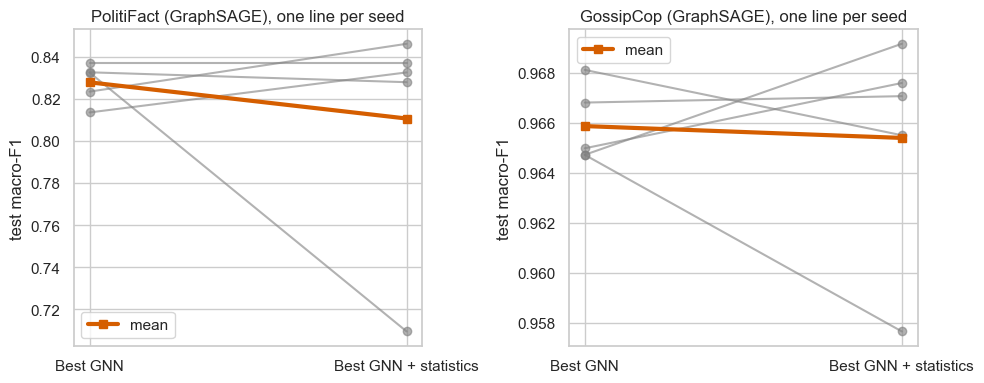

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
for ax, ds in zip(axes, DATASETS):
    r = RESULTS[RESULTS["dataset_key"] == ds]
    a = r[r["variant"] == VARIANTS[False]].sort_values("seed")["f1_macro"].to_numpy()
    b = r[r["variant"] == VARIANTS[True]].sort_values("seed")["f1_macro"].to_numpy()
    for x, y in zip(a, b):
        ax.plot([0, 1], [x, y], color="grey", alpha=0.6, marker="o")
    ax.plot([0, 1], [a.mean(), b.mean()], color="#D55E00", lw=3, marker="s", label="mean")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Best GNN", "Best GNN + statistics"])
    ax.set_ylabel("test macro-F1"); ax.set_title(f"{DATASET_TITLES[ds]} ({BEST_GNN[ds]}), one line per seed"); ax.legend()
plt.tight_layout(); save_figure(fig, EXT_FIG_DIR / f"extension_paired_macro_f1_{SETTING}.png"); plt.show()

## 7 · Observations

In [15]:
lines = []
for _, r in DIFFS.iterrows():
    sign = "higher" if r["Difference (mean)"] > 0 else "lower"
    lines.append(f"[{r['Dataset']}] {r['GNN']}: macro-F1 with statistics is {abs(r['Difference (mean)']):.3f} {sign} on average "
                 f"({r['Macro F1 without']:.3f} to {r['Macro F1 with']:.3f}); improved in {r['Seeds improved']} seeds; paired t-test p = {r['Paired t-test p']:.3f}.")
    spread = RESULTS[(RESULTS["dataset"] == r["Dataset"]) & (RESULTS["variant"] == VARIANTS[False])]["f1_macro"].std()
    lines.append(f"[{r['Dataset']}] seed-to-seed std of the model without statistics: {spread:.3f}; "
                 + ("the mean difference is smaller than this std." if abs(r["Difference (mean)"]) < spread else "the mean difference is larger than this std."))
print("\n".join("- " + l for l in lines))

- [PolitiFact] GraphSAGE: macro-F1 with statistics is 0.017 lower on average (0.828 to 0.811); improved in 2/5 seeds; paired t-test p = 0.559.
- [PolitiFact] seed-to-seed std of the model without statistics: 0.009; the mean difference is larger than this std.
- [GossipCop] GraphSAGE: macro-F1 with statistics is 0.000 lower on average (0.966 to 0.965); improved in 3/5 seeds; paired t-test p = 0.827.
- [GossipCop] seed-to-seed std of the model without statistics: 0.002; the mean difference is smaller than this std.


Notes:
- Five seeds and a small PolitiFact test split give wide uncertainty; the paired t-test with 5 pairs has little power.
- Statistics describe graph size and shape only. Their effect depends on how much of that information the GNN already captures through pooling.
- The best GNN is chosen on validation macro-F1 from notebook 03; the test set is not used for any choice.

## 8 · Saved files

In [16]:
inventory = pd.DataFrame(SAVED_ARTIFACTS)
display(inventory)

,kind,path,size_kB
0,csv,results\metrics\extension\statistics_used.csv,436.8
1,csv,results\metrics\extension\extension_metrics.csv,7.5
2,csv,results\metrics\extension\extension_summary.csv,0.4
3,csv,results\metrics\extension\extension_difference...,0.3
4,figure,results\figures\extension\extension_paired_mac...,82.4
